# 5. Raster Operations

In [1]:
from pathlib import Path
import xarray as xr
import rioxarray as rxr
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib_map_utils import north_arrow, scale_bar, inset_map

In [2]:
input_path = Path('/home/lorem/Data/R10m/')

path_dict = {
    'red': 4,
    'green': 3,
    'blue': 2,
    'nir': 8
}

bands = {

    k: 
    
    rxr.open_rasterio(
        input_path / f'T32ULC_20260915T103701_B{v:02d}_10m.jp2',
        masked=True
    ).squeeze(
        'band',
        drop=True
    )
    
    for k, v in path_dict.items()
}

In [3]:
bands['red']

<xarray.DataArray (y: 10980, x: 10980)> Size: 482MB
[120560400 values with dtype=float32]
Coordinates:
  * y            (y) float64 88kB 5.8e+06 5.8e+06 5.8e+06 ... 5.69e+06 5.69e+06
  * x            (x) float64 88kB 3e+05 3e+05 3e+05 ... 4.098e+05 4.098e+05
    spatial_ref  int64 8B 0
Attributes:
    scale_factor:  1.0
    add_offset:    0.0

In [4]:
rgbn = xr.concat(
    [v for v in bands.values()],
    dim='band'
).assign_coords(
    band=[v for v in path_dict.values()]
)

In [5]:
rgbn.rio.resolution()

(10.0, -10.0)

In [6]:
rgbn.shape

(4, 10980, 10980)

In [7]:
rgbn.dims

('band', 'y', 'x')

In [8]:
rgbn.coords

Coordinates:
  * band         (band) int64 32B 4 3 2 8
  * y            (y) float64 88kB 5.8e+06 5.8e+06 5.8e+06 ... 5.69e+06 5.69e+06
  * x            (x) float64 88kB 3e+05 3e+05 3e+05 ... 4.098e+05 4.098e+05
    spatial_ref  int64 8B 0

In [9]:
rgbn.attrs

{'scale_factor': 1.0, 'add_offset': 0.0}

In [10]:
rgbn.dtype

dtype('float32')

In [11]:
rgbn.rio.transform()

Affine(10.0, 0.0, 300000.0,
       0.0, -10.0, 5800020.0)

In [12]:
rgbn.rio.bounds()

(300000.0, 5690220.0, 409800.0, 5800020.0)

In [13]:
print(rgbn.rio.crs)

EPSG:32632


In [14]:
gpkg_path = Path('../data/outputs/netherlands.gpkg')

country = gpd.read_file(
    gpkg_path,
    layer='country'
)

cities = gpd.read_file(
    gpkg_path,
    layer='cities'
)

enschede = cities[
    cities['name']=='Enschede'
]

rgbn = rgbn.rio.clip(
    enschede.geometry.tolist(),
    crs=enschede.crs
)

rgbn.rio.bounds()

(346700.0, 5781070.0, 362090.0, 5794850.0)

In [15]:
rgbn = rgbn.rio.reproject(enschede.crs)
print(rgbn.rio.crs)

EPSG:28992


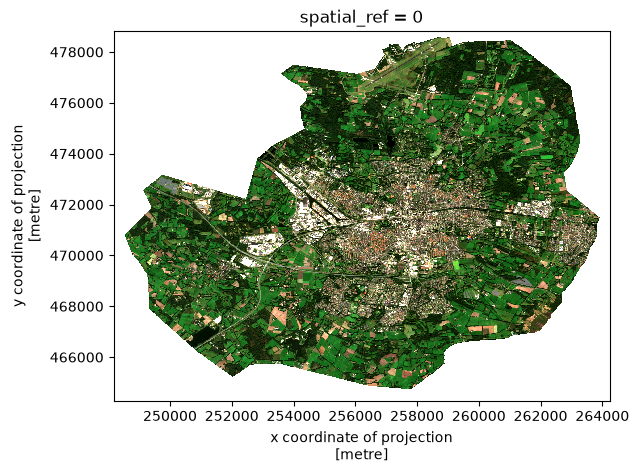

In [16]:
rgbn.sel(
    band=[4,3,2]
).plot.imshow(
    robust=True
)

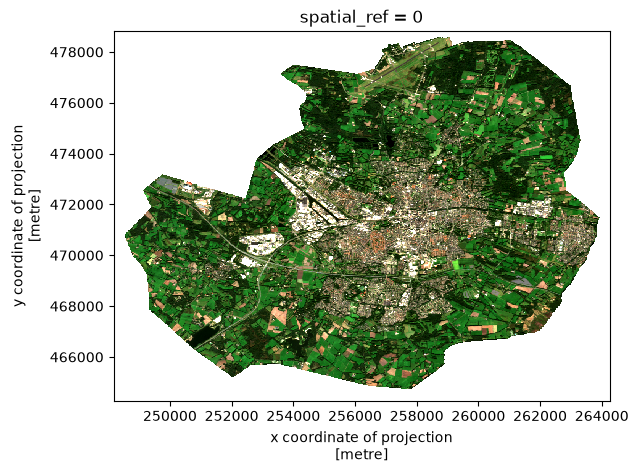

In [17]:
downsampled = rgbn.rio.reproject(
    dst_crs=rgbn.rio.crs,
    resolution=20,
    resampling='average'
)

downsampled.sel(
    band=[4,3,2]
).plot.imshow(
    robust=True
)

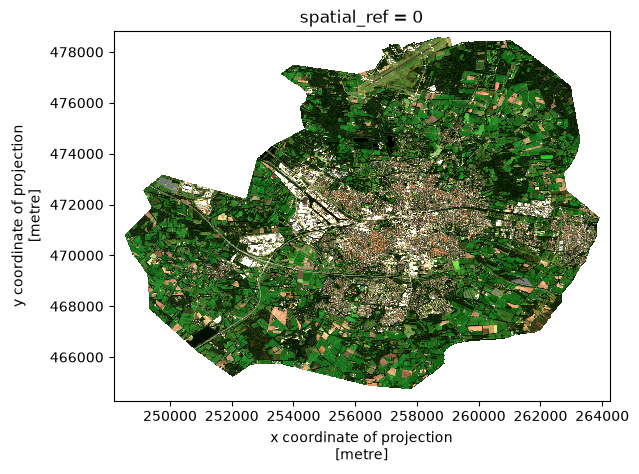

In [18]:
upsampled = rgbn.rio.reproject(
    dst_crs=rgbn.rio.crs,
    resolution=5,
    resampling='average'
)

upsampled.sel(
    band=[4,3,2]
).plot.imshow(
    robust=True
)

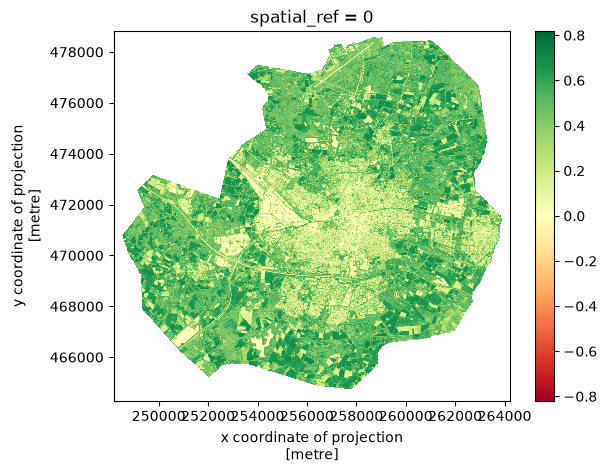

In [19]:
nir = rgbn.sel(band=8)
red = rgbn.sel(band=4)

ndvi = (nir - red) / (nir + red)

ndvi.plot.imshow(
    cmap='RdYlGn'
)

In [20]:
print(ndvi.min().item())
print(ndvi.max().item())
print(ndvi.mean().item())

-0.3269333243370056
0.8187319040298462
0.41830185055732727


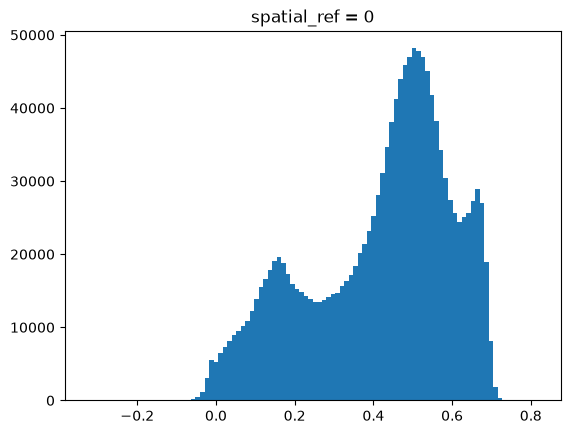

In [21]:
ndvi.plot.hist(
    bins=100
)

plt.show()

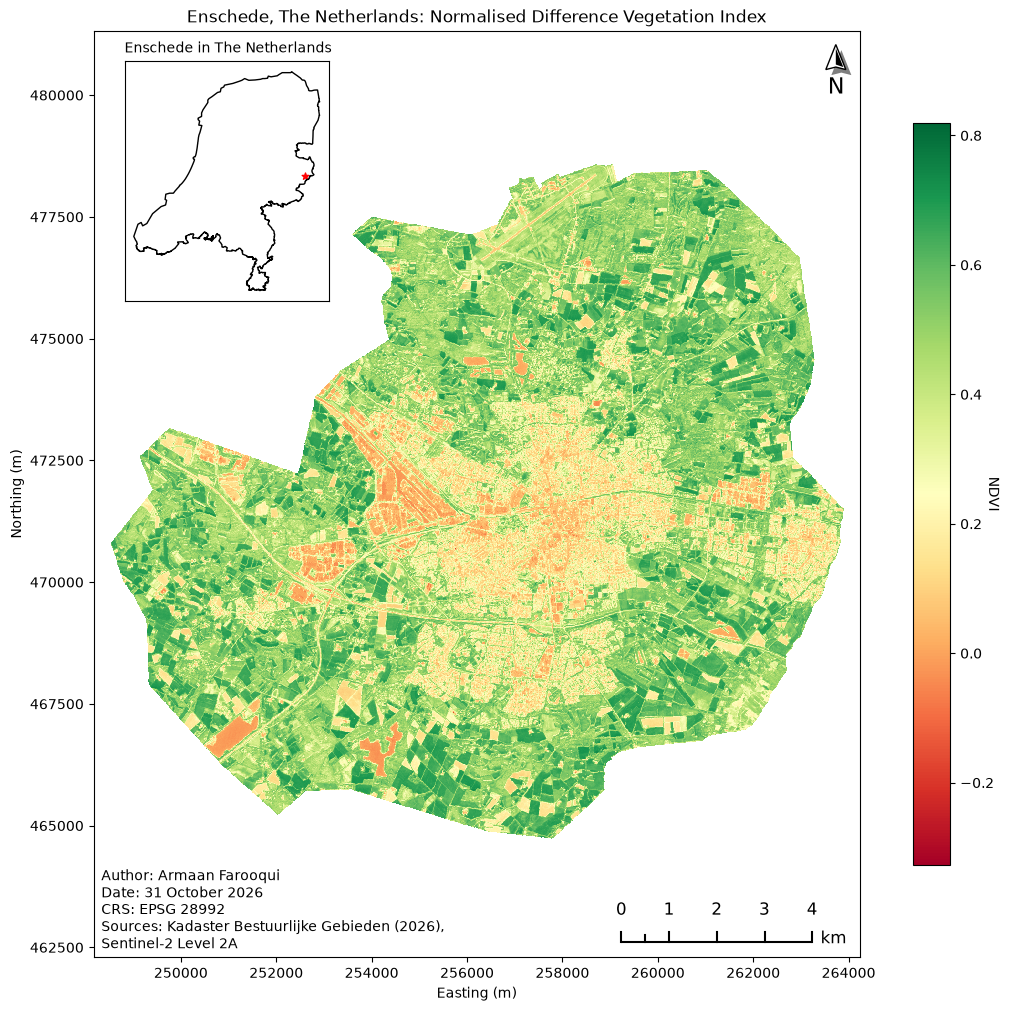

In [22]:
export_path = Path('../data/outputs')

fig, ax = plt.subplots(
    figsize=(10,10),
    constrained_layout=True
)

im = ndvi.plot.imshow(
    ax=ax,
    cmap='RdYlGn',
    vmin=ndvi.min().item(),
    vmax=ndvi.max().item(),
    cbar_kwargs={
        'shrink':0.8
    }
)

im.colorbar.set_label(
    'NDVI',
    rotation=270
)

north_arrow(
    ax=ax,
    location='upper right',
    scale=0.25
)

scale_bar(
    ax=ax,
    location='lower right',
    style='ticks',
    bar={
        'projection':ndvi.rio.crs,
        'length':2
    }
)

inset = inset_map(
    ax=ax,
    location='upper left'
)

enschede_centroid = enschede.geometry.centroid

inset.scatter(
    x=enschede_centroid.x,
    y=enschede_centroid.y,
    s=25,
    color='red',
    marker='*'
)

country.plot(
    ax=inset,
    color='none'
)

inset.set(
    xlabel='',
    ylabel='',
    xticks=[],
    yticks=[]
)

inset.set_title(
    'Enschede in The Netherlands',
    fontsize=10,
    loc='left'
)

ymin, ymax = ax.get_ylim()

ax.text(
    x=0.01,
    y=0.01,
    s='Author: Armaan Farooqui\n'
    'Date: 31 October 2026\n'
    'CRS: EPSG 28992\n'
    'Sources: Kadaster Bestuurlijke Gebieden (2026),\n'
    'Sentinel-2 Level 2A',
    transform=ax.transAxes
)

ax.set(
    title='Enschede, The Netherlands: Normalised Difference Vegetation Index',
    xlabel='Easting (m)',
    ylabel='Northing (m)',
    ylim=(ymin - 2000, ymax + 2500)
)

plt.savefig(
    export_path / 'enschede_ndvi.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

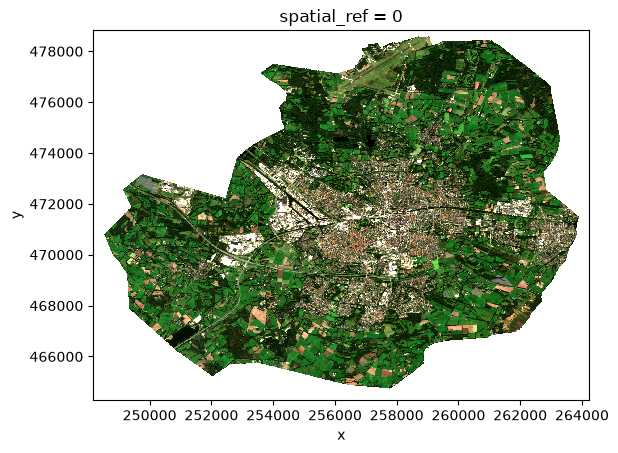

In [23]:
rgbn = rgbn.fillna(-9999).rio.write_nodata(-9999)

rgbn.rio.to_raster(
    export_path / 'enschede.tif',
    driver='GTiff',
    compress='DEFLATE',
    predictor=3,
    tiled=True,
    blockxsize=256,
    blockysize=256
)

rxr.open_rasterio(
    export_path / 'enschede.tif',
    masked=True
).sel(
    band=[1,2,3]
).plot.imshow(
    robust=True
)